In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
#import squidpy as sq
import anndata as ad

import warnings
#import squidpy as sq

  
warnings.simplefilter("ignore", category=UserWarning)
warnings.simplefilter("ignore", category=FutureWarning)  

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: 

In [2]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
#%matplotlib inline
sc.settings.figdir = "fig1"
sc.settings.set_figure_params(dpi_save=300, facecolor="white", frameon=False, figsize=(8,8))


In [3]:
#PATH = '/nfs/team298/ls34/adult_skin/final_adatas/adata_combined_new.h5ad.final.filtered'
PATH = '/nfs/team298/ls34/adult_skin/final_adatas/adata_combined_inc_relapse_webportal.h5ad'
adata=sc.read_h5ad(PATH)


 

In [4]:
adata.obs.sample_id.nunique()
# note that some sample id's contain multiple tissue sections

448

In [5]:
adata.obs.sample_id.isna().sum()

0

In [6]:
adata.obs.sample_id.value_counts()

sample_id
3D_BK25_week12-D2                                                                       41325
output-XETG00272__0081038__BK73-SKI-26-FO-3-s2_BK74-SKI-27-FO-1-s2__20260413__125221    32171
BK39_Week 12                                                                            32058
BK30_Day 14                                                                             30438
Healthy1                                                                                29833
                                                                                        ...  
GSM5277170                                                                               1027
GSM6111844                                                                               1014
GSM6165458                                                                               1012
GSM5652708                                                                               1012
GSM6111854                                        

In [7]:
adata.obs.info_id6.nunique()

113

In [8]:
adata_i=adata[adata.obs["tech"]!="xenium"]
adata_i.obs.sample_id.nunique()


338

In [4]:
adata_i=adata[adata.obs["tech"]=="xenium"].copy()


# set colors

In [5]:
# # red white
# colors2 = { "scrna": "#F8F4E3",
#              "xenium": "#6FAEF3", #"#0474ed", # red"#D23C3C"
#           }

# adata.obs['tech'] =adata.obs['tech'] .astype('category')
# adata.uns['tech_colors'] = [colors2.get(cat, '#D3D3D3')  # Default to light grey if not found
#                                      for cat in adata.obs['tech'].cat.categories]


# joint integration umap

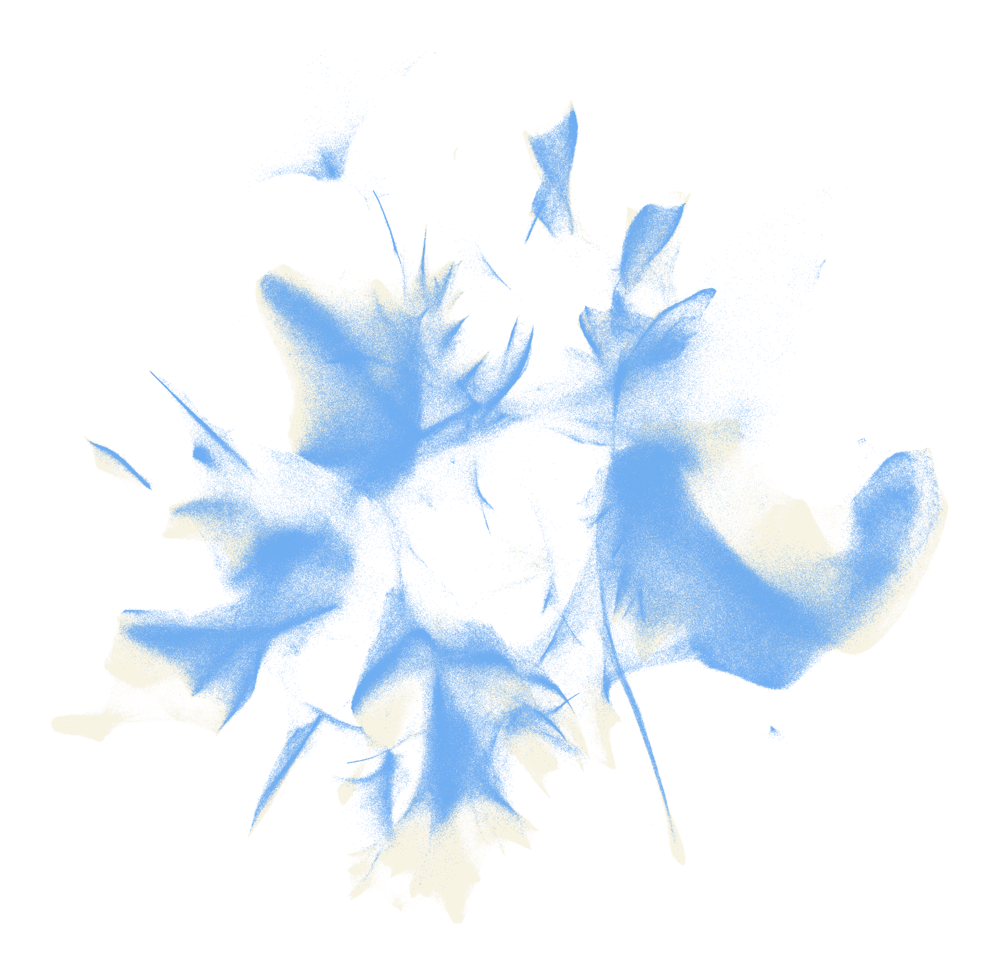

(3401466, 4993)


In [6]:
sc.settings.set_figure_params(dpi=50, dpi_save=300, facecolor="white", frameon=False, figsize=(21,21))
sc.pl.umap(
    adata,
    color=[ "tech"],
    show=True,
    frameon=False,
    legend_loc= None,
    legend_fontsize=12,
    s=1,
    title='',
    legend_fontoutline=2,
    save="1a_joint_umap.pdf"
  #save="1a_scrna.pdf",
 #   linewidth=0.01,
  #  edgecolor='black'
)
print(adata.shape)

# xenium

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


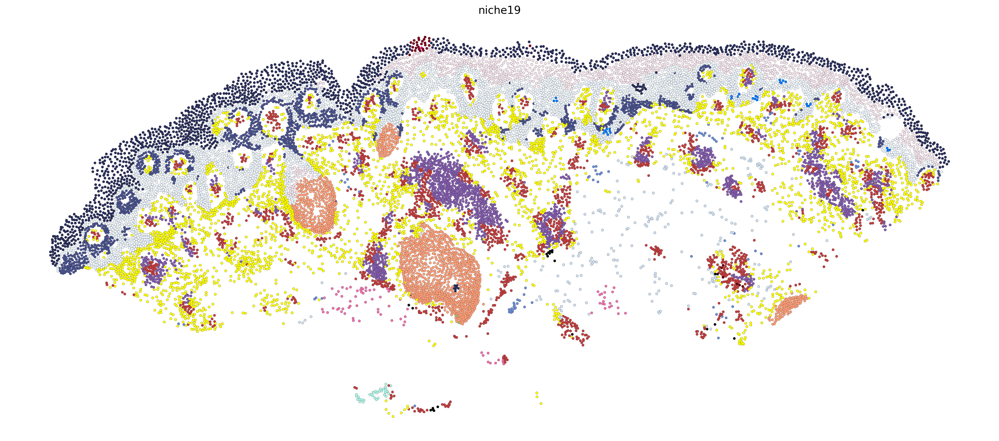

In [8]:
sc.settings.set_figure_params(dpi=100,  dpi_save=300, facecolor="white", frameon=False, figsize=(18,18))
import squidpy as sq
adata_hair = adata[adata.obs["Sanger patient ID"]=="BK39"]
adata_hair = adata_hair[adata_hair.obs["Timepoint"].str.startswith("L")]
adata_hair=adata_hair.copy()

 


sq.pl.spatial_scatter(
    adata_hair,#[adata_i.obs["Timepoint"].str.startswith("Les")],
    library_id="spatial",
    shape=None,
    color="niche19",
    size=40,
    vmax=1,
    #title=str(STATUS) + "_" + DONOR_ID,
    #title=INFO_ID, #+ "_nonlesional",
   legend_loc=None,
            edgecolor="black",
    linewidth=0.1,
            legend_fontsize=12,
        save="1a_niche_example.pdf"


    #ax=ax,
    #legend_loc="on data"  # Disable the legend for each subplot
)
#    

In [9]:


# sc.pl.spatial(
#     adata_hair,#[adata_i.obs["Timepoint"].str.startswith("Les")],
#     #library_id="spatial",
#     #shape=None,
#     color="niche19",
#     spot_size=15,
#     vmax=1,
#     #title=str(STATUS) + "_" + DONOR_ID,
#     #title=INFO_ID, #+ "_nonlesional",
#    legend_loc=None,
#             edgecolor="black",
#     linewidth=0.3,
#             legend_fontsize=12,
#         save="1a_celltype_example.pdf",
#     palette=colors,


#     #ax=ax,
#     #legend_loc="on data"  # Disable the legend for each subplot
# )
# #    

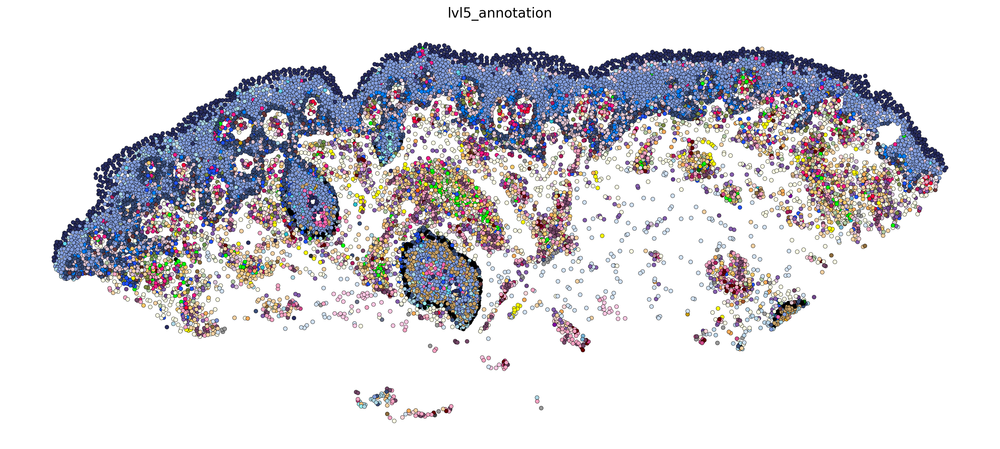

In [11]:


sc.pl.spatial(
    adata_hair,#[adata_i.obs["Timepoint"].str.startswith("Les")],
    #library_id="spatial",
    #shape=None,
    color="lvl5_annotation",
    spot_size=15,
    vmax=1,
    #title=str(STATUS) + "_" + DONOR_ID,
    #title=INFO_ID, #+ "_nonlesional",
   legend_loc=None,
            edgecolor="black",
    linewidth=0.3,
            legend_fontsize=12,
        save="1a_celltype_example.pdf",
    #palette=colors,


    #ax=ax,
    #legend_loc="on data"  # Disable the legend for each subplot
)
#    

# spatial celltypes icon

Week 8 (resolved)_CE5-SKI-27-FO-4-S22-E1


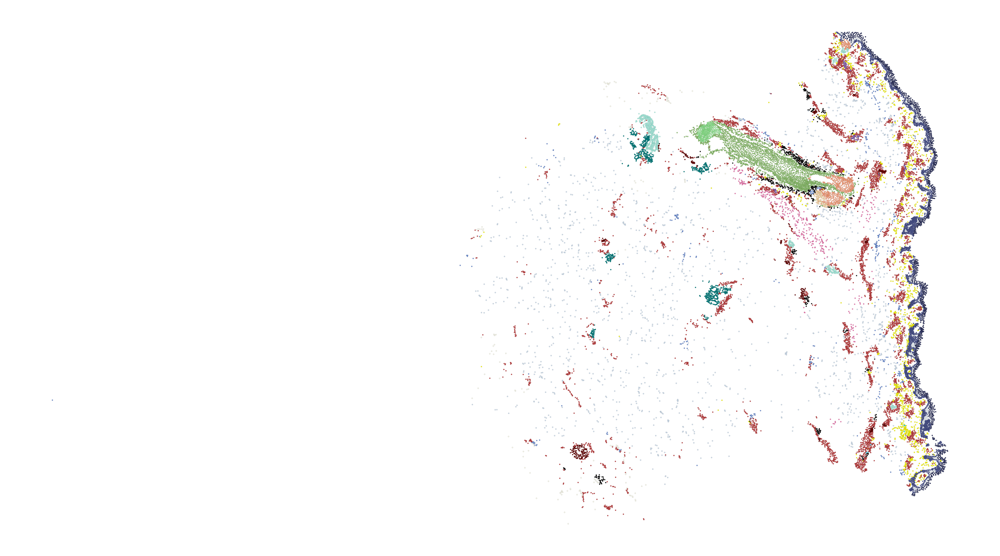

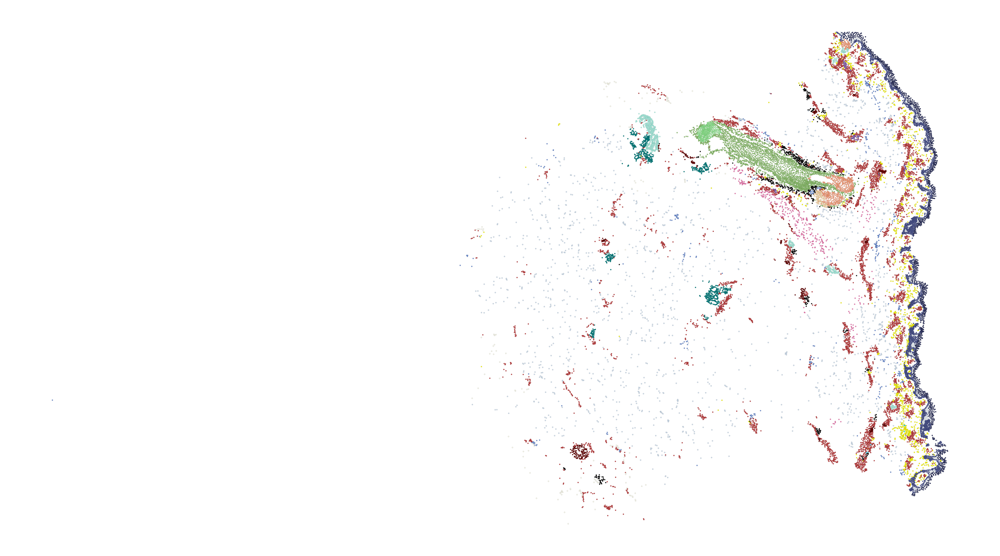

In [12]:
SAMPLES= [#'BK49_Past Lesional', 
    'Week 8 (resolved)_CE5-SKI-27-FO-4-S22-E1']

for i,x in enumerate(SAMPLES):
    adata_i=adata[adata.obs["info_id6"]==x]
    # adata_i.obs['niche19'] =adata_i.obs['niche19'] .astype('category')
    # adata_i.uns['niche19_colors'] = [colors_new2.get(cat, '#D3D3D3')  # Default to light grey if not found
    #                                  for cat in adata_i.obs['niche19'].cat.categories]
    print(x)
    sc.pl.spatial(
        adata_i,#[adata_i.obs["Timepoint"].str.startswith("Les")],
        #library_id="spatial",
        #shape=None,
        color="niche19",
        spot_size=10,
        vmax=1,
        #title=str(STATUS) + "_" + DONOR_ID,
        #title=INFO_ID, #+ "_nonlesional",
     legend_loc=None,
        # legend_loc="on data",
                edgecolor="black",
        linewidth=0.05,
                legend_fontsize=12,
        title="",
         save = f"fig1a_{x}_byniche.pdf"
        #save="fig2_day14_by_niche_legend.pdf"

        #ax=ax,
        #legend_loc="on data"  # Disable the legend for each subplot
    )
    sc.pl.spatial(
        adata_i,#[adata_i.obs["Timepoint"].str.startswith("Les")],
        #library_id="spatial",
        #shape=None,
        color="niche19",
        spot_size=10,
        vmax=1,
        #title=str(STATUS) + "_" + DONOR_ID,
        #title=INFO_ID, #+ "_nonlesional",
     legend_loc=None,
        # legend_loc="on data",
                edgecolor="black",
        linewidth=0.05,
                legend_fontsize=12,
        title="",
         save = f"fig1a_{x}_byniche_WITHLEGEND.pdf"
        #save="fig2_day14_by_niche_legend.pdf"

        #ax=ax,
        #legend_loc="on data"  # Disable the legend for each subplot
    )
    if i>30:
        break

Week 8 (resolved)_CE5-SKI-27-FO-4-S22-E1


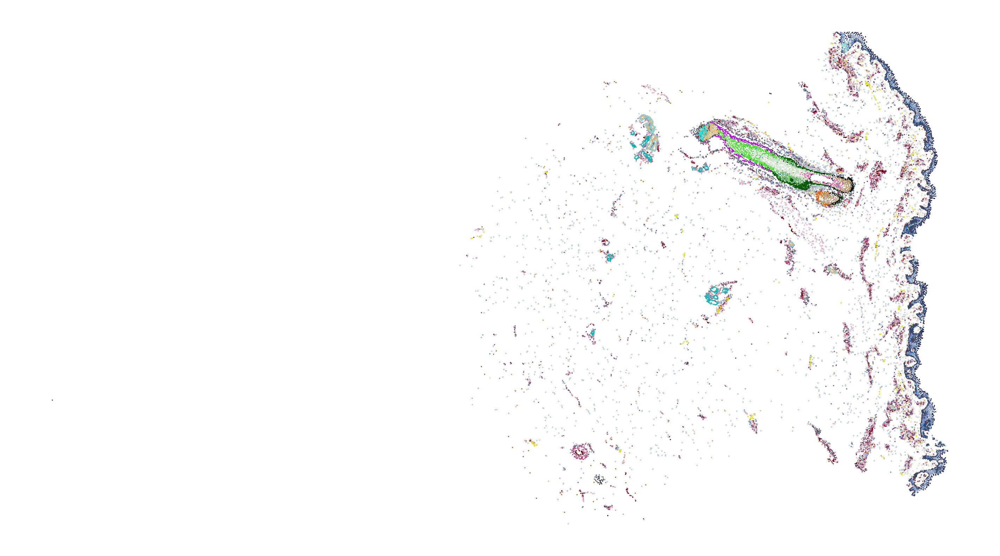

In [13]:
for i,x in enumerate(SAMPLES):
    adata_i=adata[adata.obs["info_id6"]==x]
    # adata_i.obs['lvl5_annotation'] =adata_i.obs['lvl5_annotation'] .astype('category')
    # adata_i.uns['lvl5_annotation_colors'] = [colors.get(cat, '#D3D3D3')  # Default to light grey if not found
    #                                  for cat in adata_i.obs['lvl5_annotation'].cat.categories]
    print(x)
    sc.pl.spatial(
        adata_i,#[adata_i.obs["Timepoint"].str.startswith("Les")],
        #library_id="spatial",
        #shape=None,
        color="lvl5_annotation",
        spot_size=10,
        vmax=1,
        #title=str(STATUS) + "_" + DONOR_ID,
        #title=INFO_ID, #+ "_nonlesional",
     legend_loc=None,
        # legend_loc="on data",
                edgecolor="black",
        linewidth=0.05,
                legend_fontsize=12,
        title="",
       # save = f"fig1a_{x}.pdf"
        #save="fig2_day14_by_niche_legend.pdf"

        #ax=ax,
        #legend_loc="on data"  # Disable the legend for each subplot
    )
    # if i>0:
    #     break



# cell embedding icon

In [14]:
import gc
del(adata_hair)
del(adata)
gc.collect()

20258

In [16]:
#PATH = '/nfs/team298/ls34/adult_skin/final_adatas/adata_combined_new.h5ad.final.filtered'
PATH = '/nfs/team298/ls34/adult_skin/final_adatas/adata_combined_inc_relapse_webportal.h5ad'
adata=sc.read_h5ad(PATH)
adata.obs["lvl5_annotation_new"]=adata.obs["lvl5_annotation"]
adata



 

AnnData object with n_obs × n_vars = 3401466 × 4993
    obs: 'sample_id', 'barcode', 'GSE', 'Site_status', 'Patient_status', 'dataset_id', 'lvl5_annotation', 'Mapping_status', 'scanvi_predictions', 'atlas_status_reynolds', 'atlas_status_simple', 'cell_id', 'x_centroid', 'y_centroid', 'Sanger patient ID', 'Timepoint', 'disease_overall', 'lvl0_new', 'Timepoint2', 'info_id6', 'response', 'all_vs_core', 'tech', 'scanvi_predictions2', 'lvl1_new', 'niche19', 'data_addition', 'fig1a_numbers_scrna', 'fig1_numbers_xenium_without_validation_data', 'Site_status2', 'tmp', 'lvl5_annotation_new'
    uns: 'lvl5_annotation_colors', 'niche19_colors', 'tech_colors'
    obsm: 'X_scanvi', 'X_umap', 'spatial'

In [18]:
adata.obs["Site_status_binary"]=adata.obs["Site_status"]

In [19]:
adata.obs["Patient_status"].value_counts()

Patient_status
AD                               961156
Healthy                          890036
Psoriasis                        563958
relapse                          242073
nan                              186080
3d_Lesional_baseline             175557
3d_Week12                        158233
Bullous pemphigoid                53824
SCC                               34340
Lichen planus                     22686
Prurigo                           20892
Dupuytren                         20052
Lyme_disease/Erythema migrans     17215
SCLE                              14257
Vitiligo                          11513
PSM                                9781
DLE                                7939
Wound                              7801
irAE                               4073
Name: count, dtype: int64

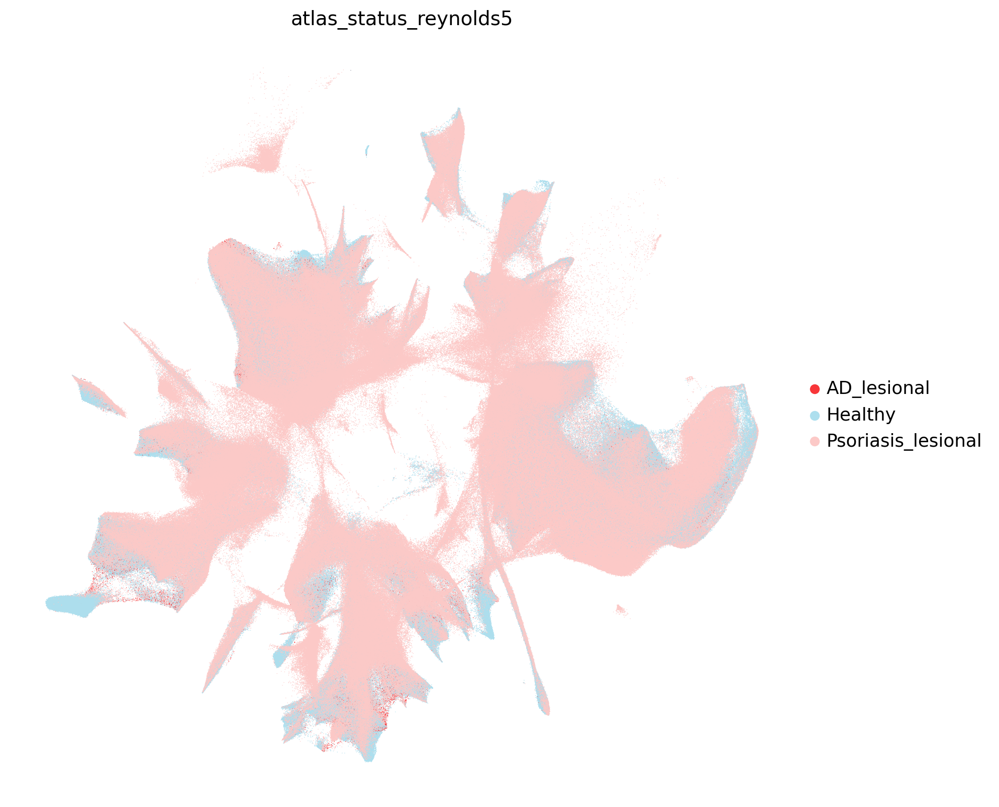

In [20]:
import numpy as np

conditions = [
    (adata.obs["Patient_status"] == "Healthy"),
    (adata.obs["Site_status_binary"] == "Nonlesional") & (adata.obs["Patient_status"] != "AD") & (adata.obs["Patient_status"] != "Psoriasis"),
    (adata.obs["Site_status_binary"] == "Nonlesional") & (adata.obs["Patient_status"] == "AD"),
    (adata.obs["Site_status_binary"] == "Nonlesional") & (adata.obs["Patient_status"] == "Psoriasis"),
    (adata.obs["Site_status_binary"] == "Lesional") & (adata.obs["Patient_status"] == "Psoriasis") & (adata.obs["dataset_id"] == "Reynolds"),
    (adata.obs["Site_status_binary"] == "Lesional") & (adata.obs["Patient_status"] == "AD") & (adata.obs["dataset_id"] == "Reynolds"),
]

choices = [
    "Healthy",
    "Nonlesional",
    "Nonlesional",
    "Nonlesional",
    "Psoriasis_lesional",
    "AD_lesional"
]

adata.obs["atlas_status_reynolds5"] = np.select(conditions, choices, default="Psoriasis_lesional")
adata.obs["atlas_status_reynolds5"].value_counts()
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc

# Define the color map for specific categories
color_map = {
    "Healthy":  "#addfee",          # Assuming "Healthy" was intended
    "Nonlesional": "#34accb",  # "#b0e1f0",
    "AD_lesional": "#f83639" , 
    "Psoriasis_lesional": "#fcc9c7",
}
adata.obs["atlas_status_reynolds5"]=adata.obs["atlas_status_reynolds5"].astype("category")
# Ensure the categories not explicitly defined in color_map get default colors
all_categories = adata.obs["atlas_status_reynolds5"].cat.categories
default_colors = sns.color_palette("tab10", len(all_categories))
category_colors = {cat: default_colors[i] for i, cat in enumerate(all_categories)}
category_colors.update(color_map)

# Generate color palette in the order of categories
palette = [category_colors[cat] for cat in adata.obs["atlas_status_reynolds5"].cat.categories]

# Plot UMAP with the customized color palette
sc.settings.set_figure_params(dpi=100, facecolor="white", frameon=False, figsize=(10, 10))
# sc.pl.umap(
#     adata, 
#     color="lvl3_annotation", 
#     frameon=False, 
#     legend_loc="on data", 
#     wspace=0.6, 
#     s=20, 
#     palette=palette
# )
sc.pl.umap(
    adata, 
    color="atlas_status_reynolds5", 
    frameon=False, 
    #legend_loc="on data", 
    wspace=0.6, 
    s=1, 
    palette=palette,
    save="1a_transfer_learning_base_umap.pdf"
)



In [21]:
adata.shape

(3401466, 4993)

In [22]:
# # sc.settings.set_figure_params(dpi=100, facecolor="white", frameon=False, figsize=(18, 18))

# sc.pl.umap(
#     adata, 
#     color="lvl0", 
#     frameon=False, 
#     #legend_loc="on data", 
#     wspace=0.6, 
#     s=3, 
#     #palette=palette
# )
# sc.settings.set_figure_params(dpi=100, facecolor="white", frameon=False, figsize=(4, 4))


Current categories: Index(['AD_lesional', 'Healthy', 'Psoriasis_lesional'], dtype='object')


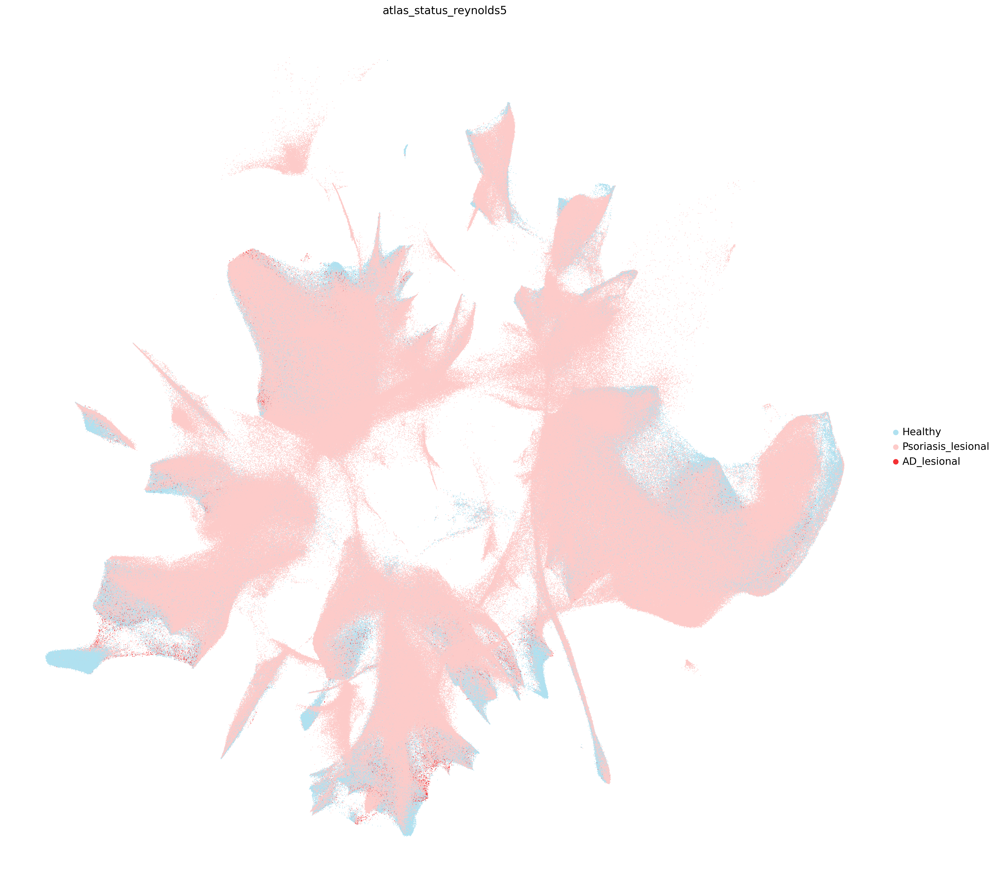

In [23]:
import seaborn as sns
import scanpy as sc

# ───────────────────────────────────────────────
# Define the color map for specific categories
# ───────────────────────────────────────────────
color_map = {
    "Healthy": "#b0e1f0",              
    "Nonlesional": "#34accb",
    "AD_lesional": "#f33033",
    "Psoriasis_lesional": "#fdcbc9"
}

# Drop unused categories first
adata.obs["atlas_status_reynolds5"] = (
    adata.obs["atlas_status_reynolds5"].cat.remove_unused_categories()
)

# Current categories
current_cats = adata.obs["atlas_status_reynolds5"].cat.categories
print("Current categories:", current_cats)

# Define desired order
desired_order = ["Healthy", "Nonlesional", "Psoriasis_lesional", "AD_lesional"]

# Keep only those categories that are actually present
valid_order = [cat for cat in desired_order if cat in current_cats]

# Reorder properly
adata.obs["atlas_status_reynolds5"] = (
    adata.obs["atlas_status_reynolds5"].cat.reorder_categories(valid_order, ordered=False)
)

# Build default colors for any category not in your map
default_colors = sns.color_palette("tab10", len(current_cats))
category_colors = {cat: default_colors[i] for i, cat in enumerate(current_cats)}
category_colors.update(color_map)

# Palette in the new category order
palette = [category_colors[cat] for cat in adata.obs["atlas_status_reynolds5"].cat.categories]

# ───────────────────────────────────────────────
# Plot UMAP
# ───────────────────────────────────────────────
sc.settings.set_figure_params(dpi=100, facecolor="white", frameon=False, figsize=(20, 20))

sc.pl.umap(
    adata, 
    color="atlas_status_reynolds5", 
    frameon=False, 
    wspace=0.6, 
    s=3, 
    palette=palette
)

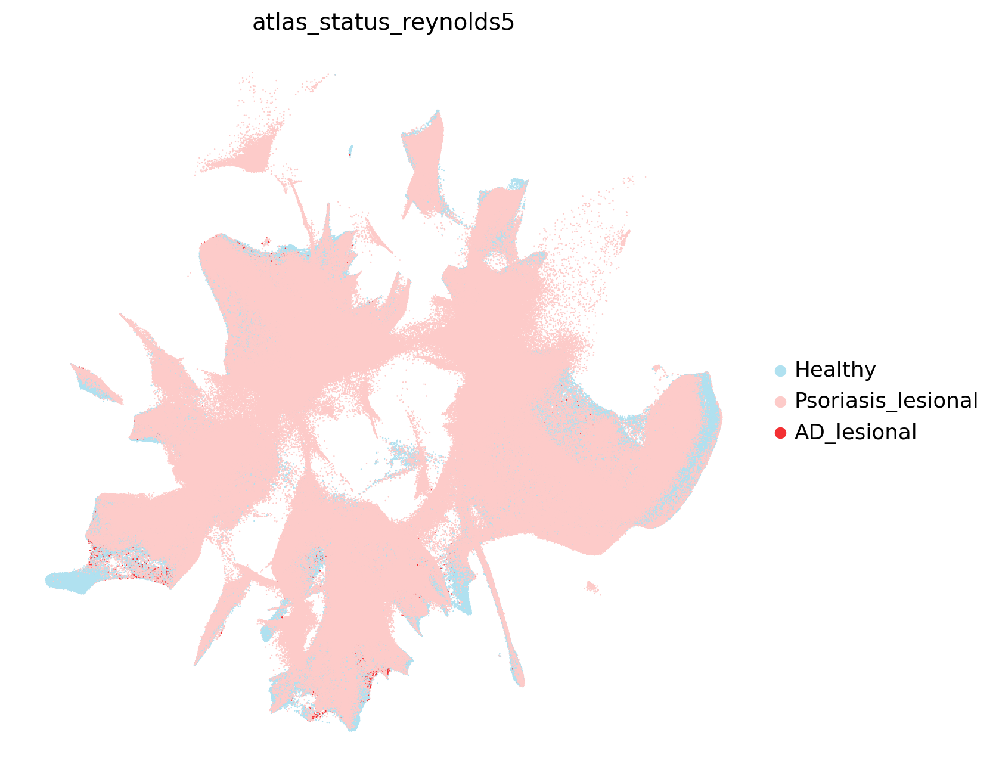

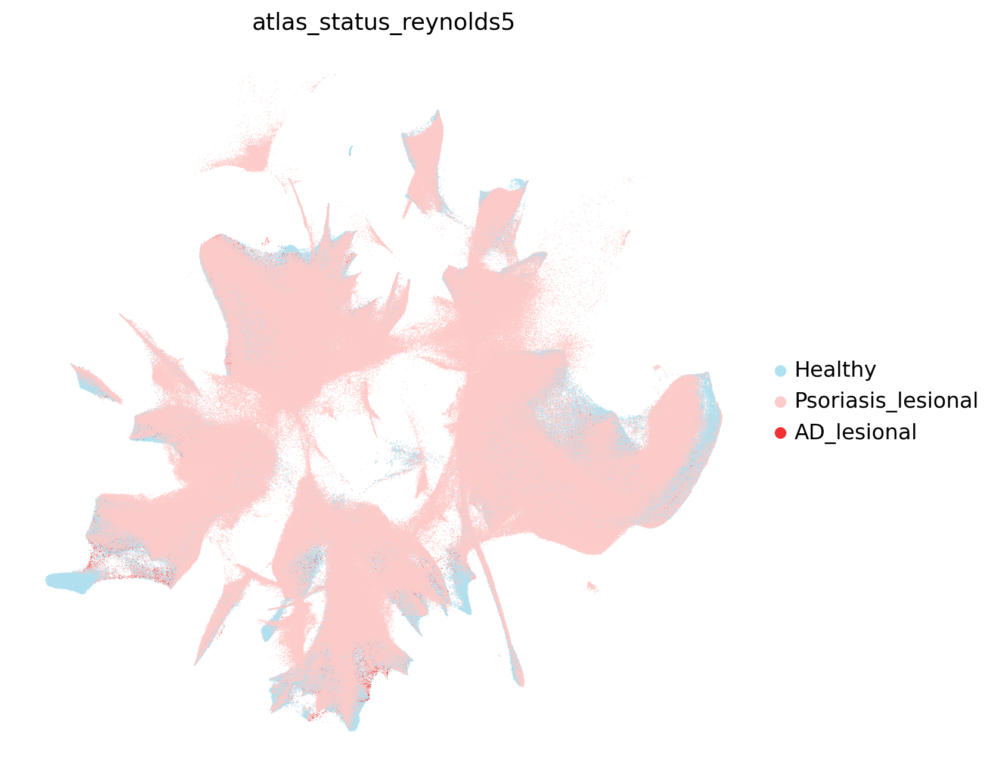

In [24]:
sc.settings.set_figure_params(dpi=100, facecolor="white", frameon=False, figsize=(8, 8))

sc.pl.umap(
    adata, 
    color="atlas_status_reynolds5", 
    frameon=False, 
    #legend_loc="on data", 
    wspace=0.6, 
    s=3, 
    palette=palette
)

sc.pl.umap(
    adata, 
    color="atlas_status_reynolds5", 
    frameon=False, 
    #legend_loc="on data", 
    wspace=0.6, 
    s=1, 
    palette=palette
)




# Niche embeddings

In [25]:
del(adata)
gc.collect()

12898

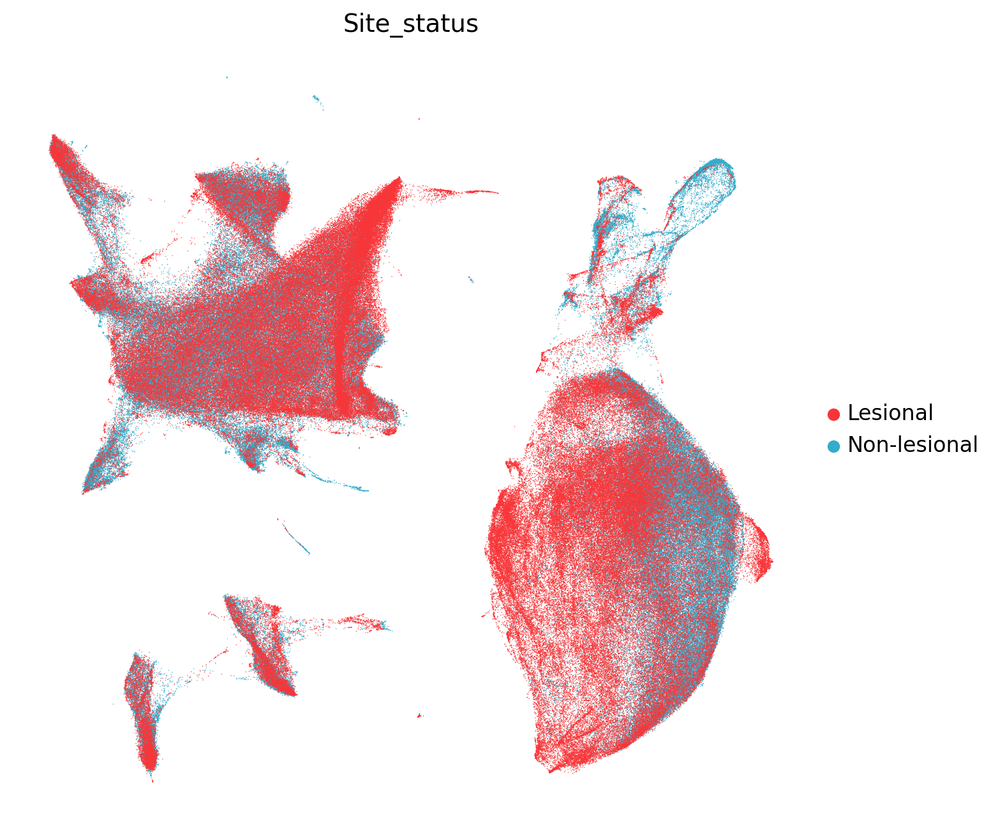

In [26]:
PATH = '/nfs/team298/ls34/adult_skin/final_adatas/adata_nicheembeddings.h5ad'
adata=sc.read_h5ad(PATH)
sc.pl.umap(adata[adata.obs["Site_status_binary"].isin(["Lesional", "Non-lesional"])], 
           color=['Site_status'  ],
           size=1, 
           #legend_loc="on data", 
           vmax="p99", 
           legend_fontsize=12,
          legend_fontoutline=2,           
           palette=[   "#f83639" , "#34accb",],
                                 save="1a_nicheembeddings.pdf"

    # "Healthy":  "#addfee",          # Assuming "Healthy" was intended
    # "Nonlesional": "#34accb",  # "#b0e1f0",
    # "AD_lesional": "#f83639" , 
    # "Psoriasis_lesional": "#fcc9c7",


          )